In [29]:
%pip install medmnist

In [30]:
import medmnist
import torch

print("MedMNIST version:", medmnist.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

MedMNIST version: 3.0.2
GPU available: True
GPU name: Tesla T4


In [31]:
from medmnist import PneumoniaMNIST

# Downloading the training, validation and test datasets
train_ds = PneumoniaMNIST(split='train', download=True)
val_ds = PneumoniaMNIST(split='val', download=True)
test_ds = PneumoniaMNIST(split='test', download=True)

print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))
print("Test samples:", len(test_ds))

Training samples: 4708
Validation samples: 524
Test samples: 624


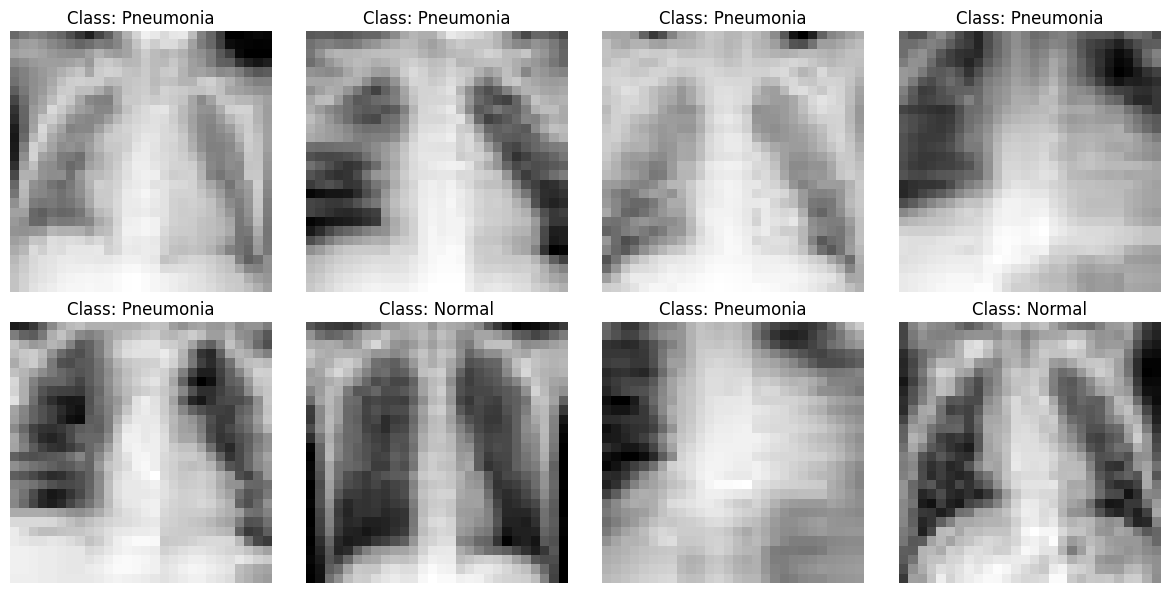

In [32]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
  image, label = train_ds[i]
  ax.imshow(image, cmap="gray")
  class_name = "Normal" if int(label[0]) == 0 else "Pneumonia"
  ax.set_title(f"Class: {class_name}")
  ax.axis("off")

plt.tight_layout()
plt.show()

In [33]:
import numpy as np
from collections import Counter

labels = np.array(train_ds.labels).flatten()

print("Image Dimensions:", train_ds.imgs.shape)
print("Training samples:", len(train_ds))
print("Class distribution:", Counter(labels))
print("Labels:0 = Normal, 1 = Pneumonia")

Image Dimensions: (4708, 28, 28)
Training samples: 4708
Class distribution: Counter({np.uint8(1): 3494, np.uint8(0): 1214})
Labels:0 = Normal, 1 = Pneumonia


In [34]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms
from medmnist import PneumoniaMNIST


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

transform = transforms.ToTensor()

train_ds = PneumoniaMNIST(split="train", download=True, transform=transform)
val_ds = PneumoniaMNIST(split="val", download=True, transform=transform)
test_ds = PneumoniaMNIST(split="test", download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

print("Data loaders ready.")

Using device: cuda
Data loaders ready.


In [35]:
class PneumoniaCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

model = PneumoniaCNN().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(model)

PneumoniaCNN(
  (network): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=1568, out_features=64, bias=True)
    (8): ReLU()
    (9): Dropout(p=0.3, inplace=False)
    (10): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [36]:
def run_epoch(loader, training=False):
  model.train() if training else model.eval()

  total_loss = 0.0
  correct = 0
  total = 0

  with torch.set_grad_enabled(training):
    for images, labels in loader:
      images = images.to(device)
      labels = labels.float().view(-1, 1).to(device)

      logits = model(images)
      loss = criterion(logits, labels)

      if training:
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

      predictions = (logits >= 0).float()
      correct += (predictions == labels).sum().item()
      total_loss += loss.item() * len(images)
      total += len(images)

  return total_loss / total, correct / total


history = []

for epoch in range(5):
  train_loss, train_acc = run_epoch(train_loader, training=True)
  val_loss, val_acc = run_epoch(val_loader, training=False)

  history.append({
      "epoch": epoch + 1,
      "train_loss": train_loss,
      "train_accuracy": train_acc,
      "val_loss": val_loss,
      "val_accuracy": val_acc
  })

  print(
      f"Epoch {epoch + 1}/5 |"
      f"Train loss: {train_loss:.4f} |"
      f"Train accuracy: {train_acc:.3f} |"
      f"Validation loss: {val_loss:.4f} |"
      f"Validation accuracy :{val_acc:.3f} "
  )

Epoch 1/5 |Train loss: 0.4379 |Train accuracy: 0.788 |Validation loss: 0.2548 |Validation accuracy :0.916 
Epoch 2/5 |Train loss: 0.2378 |Train accuracy: 0.903 |Validation loss: 0.1791 |Validation accuracy :0.947 
Epoch 3/5 |Train loss: 0.1810 |Train accuracy: 0.931 |Validation loss: 0.1501 |Validation accuracy :0.948 
Epoch 4/5 |Train loss: 0.1757 |Train accuracy: 0.933 |Validation loss: 0.1369 |Validation accuracy :0.956 
Epoch 5/5 |Train loss: 0.1531 |Train accuracy: 0.943 |Validation loss: 0.1473 |Validation accuracy :0.954 


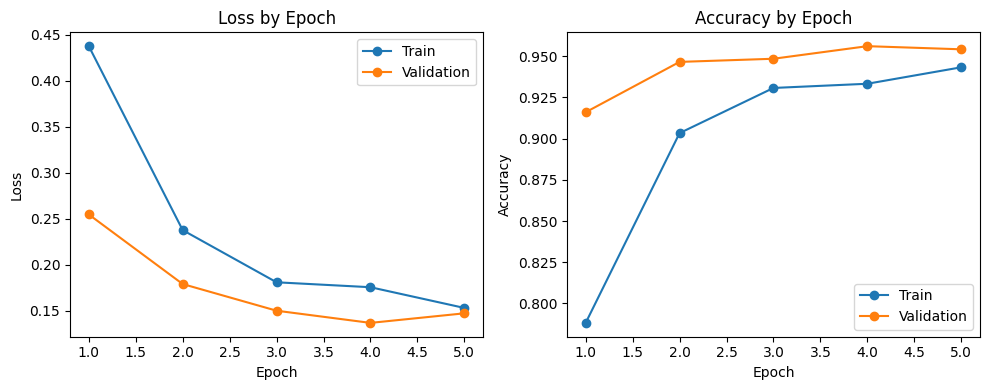

In [37]:
import matplotlib.pyplot as plt

epochs = [row["epoch"] for row in history]

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(epochs, [row["train_loss"] for row in history],
         marker="o", label="Train")
plt.plot(epochs, [row["val_loss"] for row in history],
         marker="o", label="Validation")
plt.title("Loss by Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs, [row["train_accuracy"] for row in history],
         marker="o", label="Train")
plt.plot(epochs, [row["val_accuracy"] for row in history],
         marker="o", label="Validation")
plt.title("Accuracy by Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

TEST SET CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal       0.90      0.72      0.80       234
   Pneumonia       0.85      0.95      0.90       390

    accuracy                           0.87       624
   macro avg       0.87      0.84      0.85       624
weighted avg       0.87      0.87      0.86       624

ROC-AUC: 0.9237


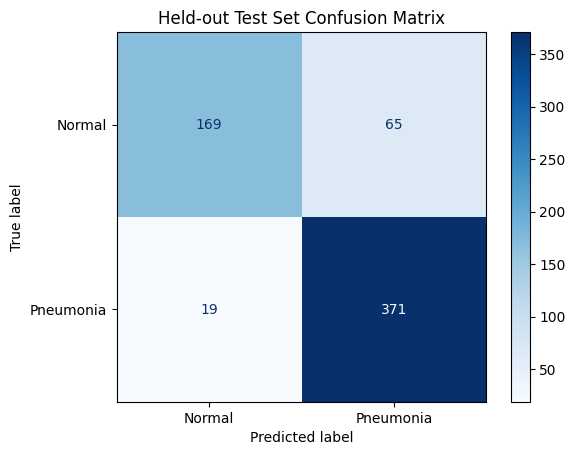

In [38]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
    confusion_matrix
)

model.eval()
all_labels = []
all_probs = []

with torch.no_grad():
  for images, labels in test_loader:
    images = images.to(device)
    logits = model(images)
    probs = torch.sigmoid(logits).cpu().numpy().ravel()

    all_probs.extend(probs)
    all_labels.extend(labels.numpy().ravel().astype(int))

all_labels = np.array(all_labels)
all_probs = np.array(all_probs)
all_preds = (all_probs >= 0.5).astype(int)

print("TEST SET CLASSIFICATION REPORT")
print(classification_report(
    all_labels,
    all_preds,
    labels=[0,1],
    target_names=["Normal","Pneumonia"],
    zero_division=0
))

print("ROC-AUC:",round(
    roc_auc_score(all_labels, all_probs), 4
))

ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(
        all_labels, all_preds, labels=[0,1]
    ),
    display_labels=["Normal","Pneumonia"]
).plot(cmap="Blues", values_format="d")

plt.title("Held-out Test Set Confusion Matrix")
plt.show()

In [39]:
print("Model available:", "model" in globals())
print("Validation loader available:", "val_loader" in globals())
print("Device:", device if "device" in globals() else "Not initialized")

Model available: True
Validation loader available: True
Device: cuda


In [40]:
import numpy as np
import torch
from sklearn.metrics import balanced_accuracy_score

model.eval()
val_labels = []
val_probs = []

with torch.no_grad():
  for images, labels in val_loader:
    images = images.to(device)
    probabilities = torch.sigmoid(model(images)).cpu().numpy().ravel()

    val_probs.extend(probabilities)
    val_labels.extend(labels.numpy().ravel().astype(int))

val_labels = np.array(val_labels)
val_probs = np.array(val_probs)

results = []

for threshold in np.arange(0.30, 0.81, 0.02):
  predictions = (val_probs >= threshold).astype(int)
  score = balanced_accuracy_score(val_labels, predictions)
  results.append((threshold,score))

best_threshold, best_score = max(results, key=lambda result: result[1])

print("Best validation threshold:", round(best_threshold, 2))
print("Validation balanced accuracy:", round(best_score, 4))


Best validation threshold: 0.5
Validation balanced accuracy: 0.9571


In [41]:
print("Selected threshold:", best_threshold)
print("Validation balanced accuracy:", best_score)

Selected threshold: 0.5000000000000002
Validation balanced accuracy: 0.9570598876511472


In [42]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [43]:
import os
import torch

save_dir = "/content/drive/MyDrive/nference_pneumonia_project"
os.makedirs(save_dir, exist_ok=True)

torch.save({
    "model_state_dict": model.state_dict(),
    "architecture": "PneumoniaCNN",
    "image_size": 28,
    "threshold": float(best_threshold)
}, os.path.join(save_dir, "pneumonia_cnn.pth"))

print("Checkpoint saved.")

Checkpoint saved.
